<center><h1>Last_First_HW6</h1></center>

Name: 
<br>
Github Username: 
<br>
USC ID: 

## 1. Tree-Based Methods

Import packages

In [117]:
%%capture
%pip install -r ../requirements.txt
from sklearn.model_selection import GridSearchCV
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from imblearn.pipeline import Pipeline
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, \
    RocCurveDisplay, accuracy_score
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

### (a) Download the APS Failure data

In [70]:
test_path = "../data/aps_failure_test_set.csv"
train_path = "../data/aps_failure_training_set.csv"

train_data = pd.read_csv(train_path, skiprows = 20, na_values = 'na')
train_data = train_data.replace({'neg': 0, 'pos': 1})
test_data = pd.read_csv(test_path, skiprows = 20, na_values = 'na')
test_data = test_data.replace({'neg': 0, 'pos': 1})

print(test_data.shape)
print(train_data.shape)

train_data['class'] = train_data['class'].astype(int)
test_data['class'] = test_data['class'].astype(int)

pos_class = train_data[train_data['class'] == 1]

#measuring missing values to assess possible imputation techniques
print(pos_class.shape)
print(pos_class.drop(columns=['class']).isna().any(axis=1).sum())

(16000, 171)
(60000, 171)
(1000, 171)
924


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Common data imputation techniques: mean imputation, median imputation, mode imputation, deletion. For this instance, median imputation is preferred as it is insulated against the numerous outliers in the training data. Row deletion would remove a vast majority of datapoints for the positive class, as 92.4% of these have at least 1 missing value. Mode imputation may default to zero, which is not always appropriate.

In [71]:
for col in train_data.columns:
    median = train_data[col].median()
    train_data[col] = train_data[col].fillna(median)

for col in test_data.columns:
    median = test_data[col].median()
    test_data[col] = test_data[col].fillna(median)

#### (ii) Calculate the coefficient of variation

In [72]:
cv_table = pd.DataFrame(np.zeros((len(train_data.columns)-1, 2)), columns=['feature', 'CV'])
temp = 0
cv_table['feature'] = cv_table['feature'].astype(str)
for col in train_data.drop(columns="class").columns:
    cv_table.loc[temp, 'feature'] = col
    mean = train_data[col].mean()
    std = train_data[col].std()
    cv_table.loc[temp, 'CV'] = std/mean
    temp = temp + 1
print(cv_table.head())

  feature          CV
0  aa_000    2.450938
1  ab_000   10.383494
2  ac_000    2.310241
3  ad_000  244.322816
4  ae_000   24.200137


#### (iii) Plot a correlation matrix

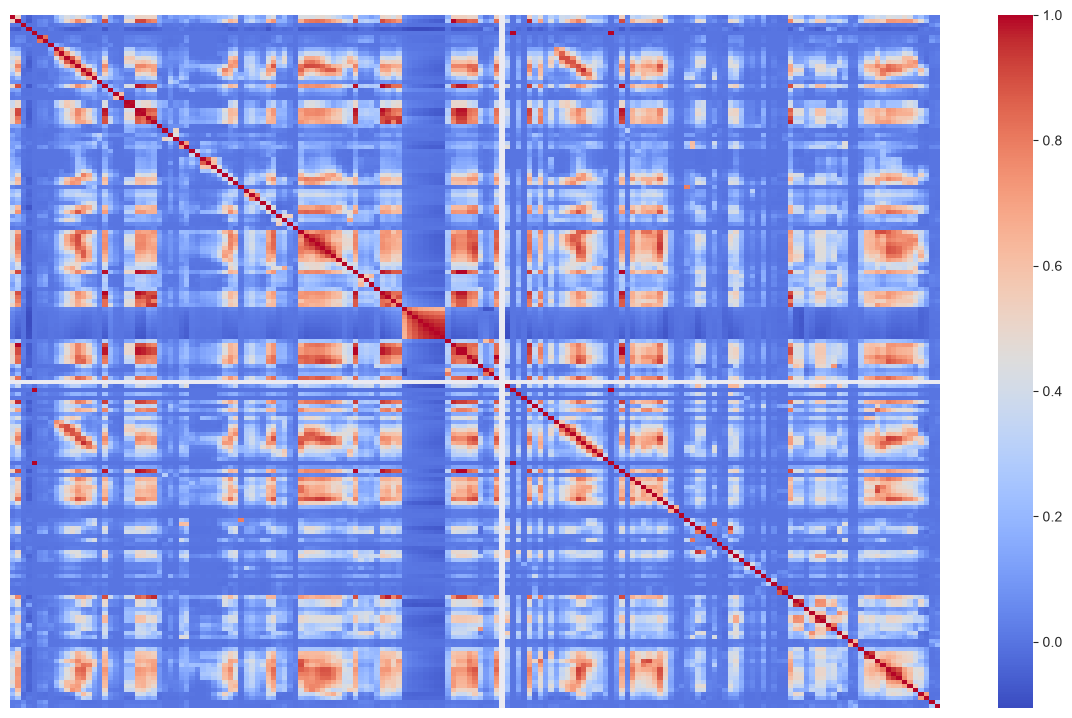

In [73]:
matrix = train_data.corr()
plt.figure(figsize=(15,9))
sns.heatmap(matrix,xticklabels=False, yticklabels=False, cmap="coolwarm")
plt.show()

#### (iv) Make scatter plots and box plots

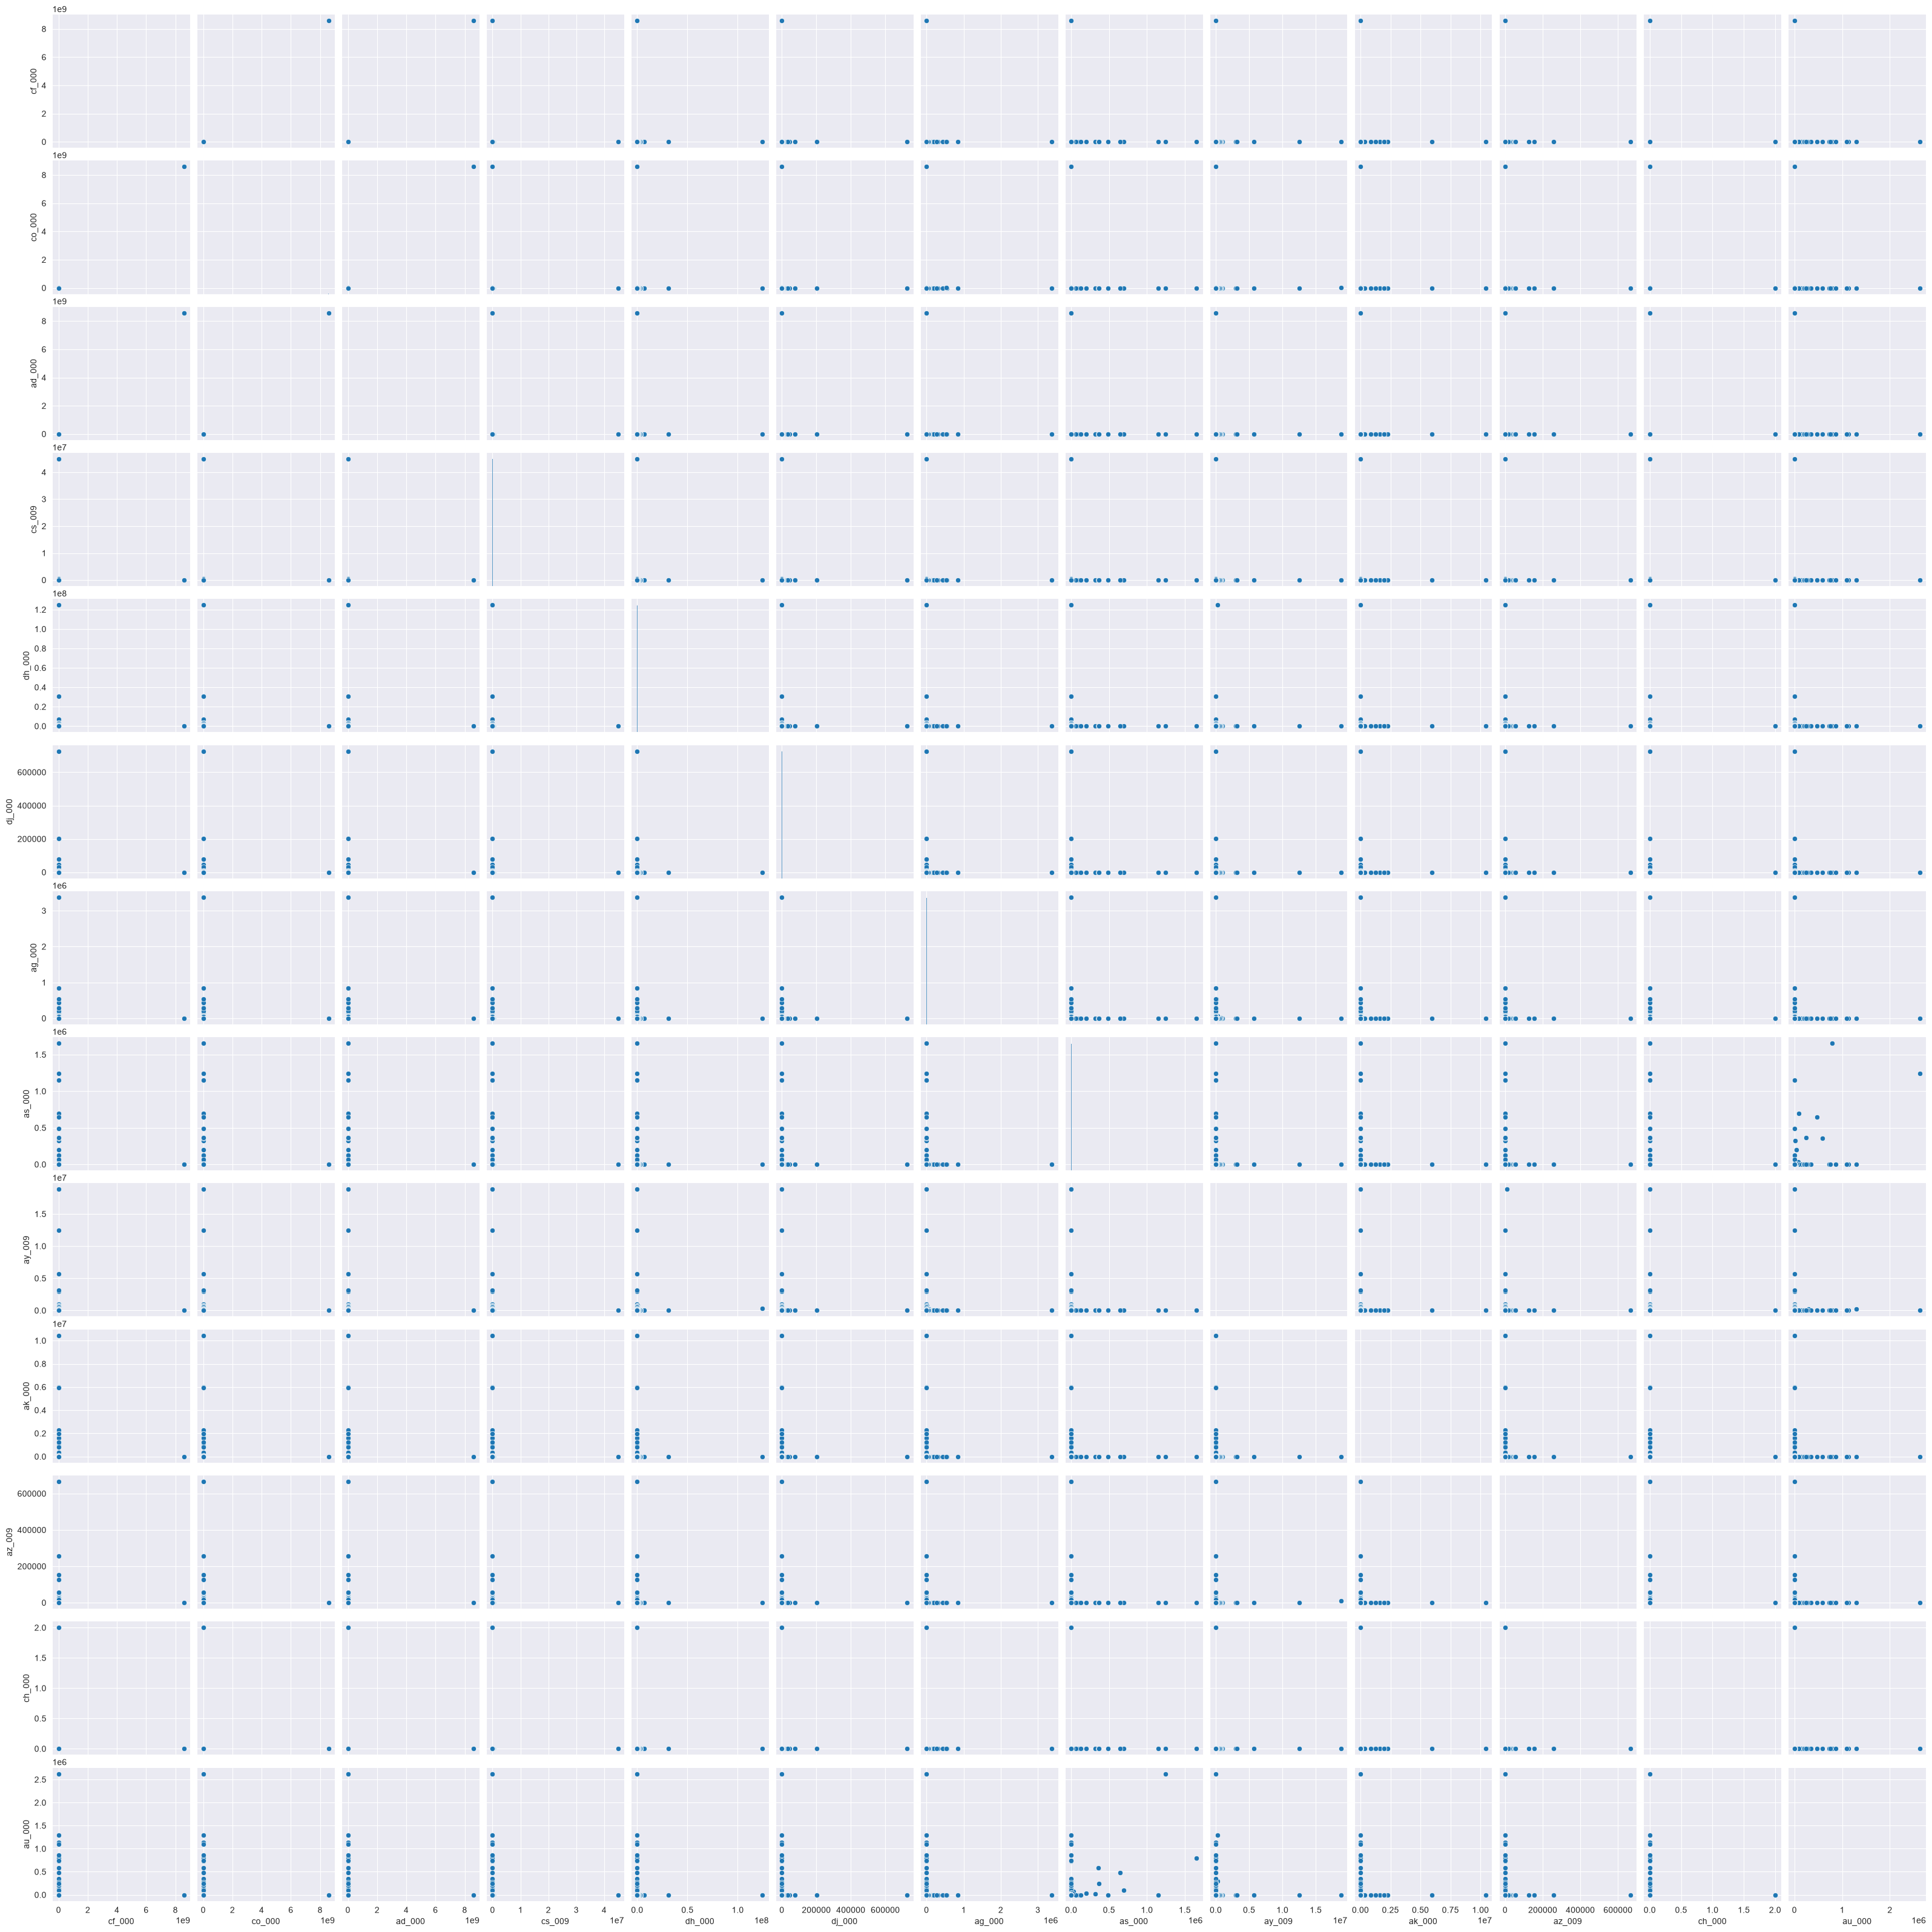

In [74]:
cv_table = cv_table.sort_values(by='CV', ascending=False)
top_features = cv_table['feature'][:13].tolist()
best_train = train_data[top_features]

sns.pairplot(best_train)

#### (v) Is this data set imbalanced?

In [75]:
#measure class ratios
positive = train_data[train_data['class'] == 1]
negative = train_data[train_data['class'] == 0]

print("Positive Classes: ", len(positive))
print("Negative Classes: ", len(negative))

Positive Classes:  1000
Negative Classes:  59000


There are 59 times more negative ('0') values for the dependent variable, so the data set is extremely unbalanced.

### (c) Train a random forest

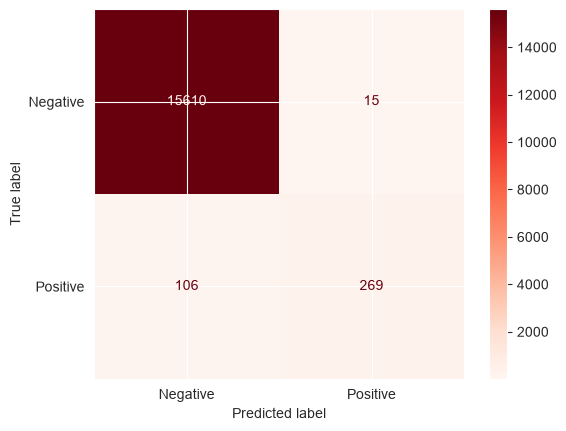

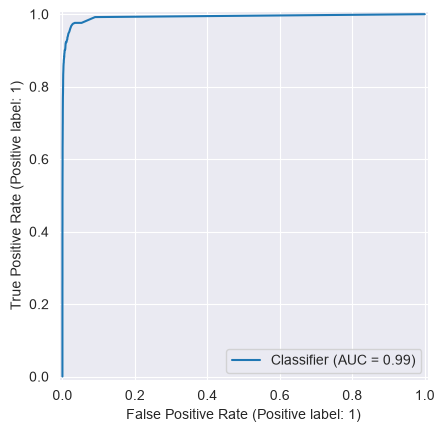

Test AUC: 0.9927564799999999
Test Error: 0.0075625000000000275
Test OOB Error: 0.006166666666666654


In [76]:
r_forest = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=42, n_jobs=-1)
r_forest.fit(train_data.drop(columns=['class']), train_data['class'])
predictions = r_forest.predict(test_data.drop(columns=['class']))

test_error = 1 - accuracy_score(test_data['class'], predictions)
test_oob_error = 1- r_forest.oob_score_

#Testing Confusion Matrix
test_c_matrix= confusion_matrix(test_data['class'], r_forest.predict(test_data.drop(columns=['class'])))
disp = ConfusionMatrixDisplay(confusion_matrix=test_c_matrix, display_labels=['Negative', 'Positive'])
disp.plot(cmap=plt.cm.Reds)
plt.show()

#ROC and AUC
test_scores = r_forest.predict_proba(test_data.drop(columns=['class']))[:, 1]
test_auc = roc_auc_score(test_data['class'], test_scores)
RocCurveDisplay.from_predictions(test_data['class'], test_scores)
plt.show()
print('Test AUC: ' + str(test_auc))
print('Test Error: ' + str(test_error))
print('Test OOB Error: ' + str(test_oob_error))

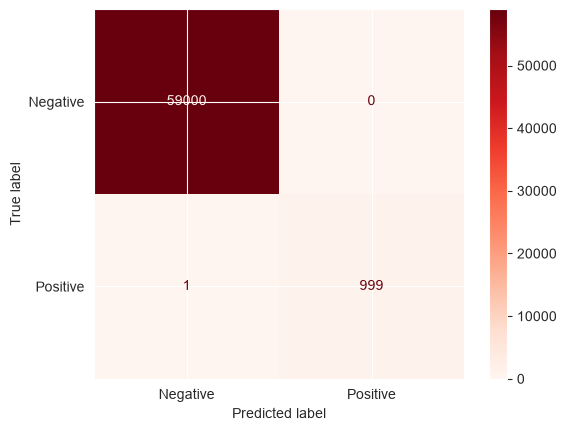

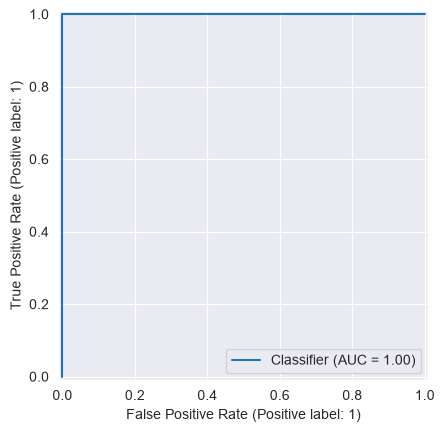

Train AUC: 1.0
Train Error: 1.666666666666483e-05
Train OOB Error: 0.006166666666666654


In [77]:
predictions = r_forest.predict(train_data.drop(columns=['class']))

error = 1 - accuracy_score(train_data['class'], predictions)
oob_error = 1- r_forest.oob_score_

#Testing Confusion Matrix
c_matrix= confusion_matrix(train_data['class'], r_forest.predict(train_data.drop(columns=['class'])))
disp = ConfusionMatrixDisplay(confusion_matrix=c_matrix, display_labels=['Negative', 'Positive'])
disp.plot(cmap=plt.cm.Reds)
plt.show()

#ROC and AUC
scores = r_forest.predict_proba(train_data.drop(columns=['class']))[:, 1]
auc = roc_auc_score(train_data['class'], scores)
RocCurveDisplay.from_predictions(train_data['class'], scores)
plt.show()
print('Train AUC: ' + str(auc))
print('Train Error: ' + str(error))
print('Train OOB Error: ' + str(oob_error))

### (d) Research class imbalance in random forest

C:\Users\johnc\PycharmProjects\DSCI552HW5\.venv\Lib\site-packages\imblearn\ensemble\_forest.py:827: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


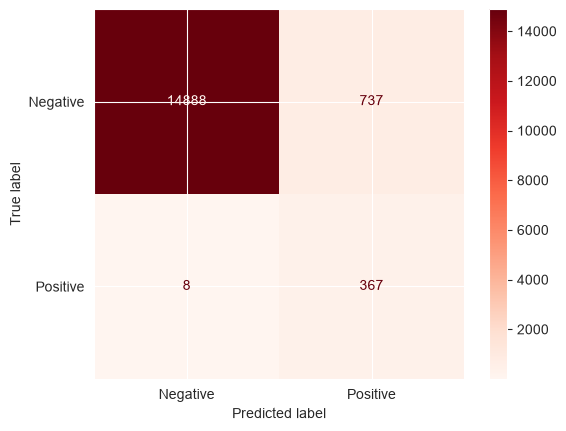

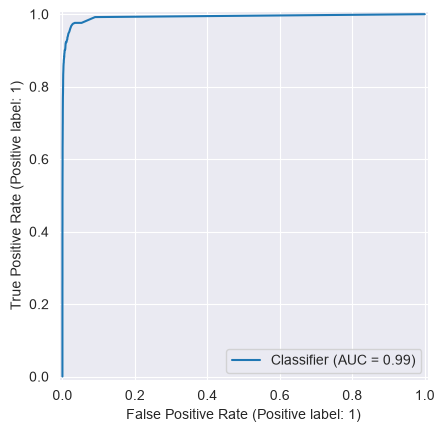

Rebalanced Test AUC: 0.9927564799999999
Rebalanced Test Error: 0.04656249999999995
Rebalanced Test OOB Error: 0.029416666666666647
Test AUC: 0.9927564799999999
Test Error: 0.0075625000000000275
Test OOB Error: 0.006166666666666654


In [78]:
bal_forest = BalancedRandomForestClassifier(n_estimators=100, bootstrap=True, oob_score=True, random_state=42, n_jobs=-1)
bal_forest.fit(train_data.drop(columns=['class']), train_data['class'])
predictions = bal_forest.predict(test_data.drop(columns=['class']))

rebalanced_test_error = 1 - accuracy_score(test_data['class'], predictions)
rebalanced_test_oob_error = 1- bal_forest.oob_score_

#Testing Confusion Matrix
test_c_matrix= confusion_matrix(test_data['class'], bal_forest.predict(test_data.drop(columns=['class'])))
disp = ConfusionMatrixDisplay(confusion_matrix=test_c_matrix, display_labels=['Negative', 'Positive'])
disp.plot(cmap=plt.cm.Reds)
plt.show()

#ROC and AUC
rebalanced_test_scores = bal_forest.predict_proba(test_data.drop(columns=['class']))[:, 1]
rebalanced_test_auc = roc_auc_score(test_data['class'], test_scores)
RocCurveDisplay.from_predictions(test_data['class'], test_scores)
plt.show()
print('Rebalanced Test AUC: ' + str(rebalanced_test_auc))
print('Rebalanced Test Error: ' + str(rebalanced_test_error))
print('Rebalanced Test OOB Error: ' + str(rebalanced_test_oob_error))
print('Test AUC: ' + str(test_auc))
print('Test Error: ' + str(test_error))
print('Test OOB Error: ' + str(test_oob_error))

C:\Users\johnc\PycharmProjects\DSCI552HW5\.venv\Lib\site-packages\imblearn\ensemble\_forest.py:827: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


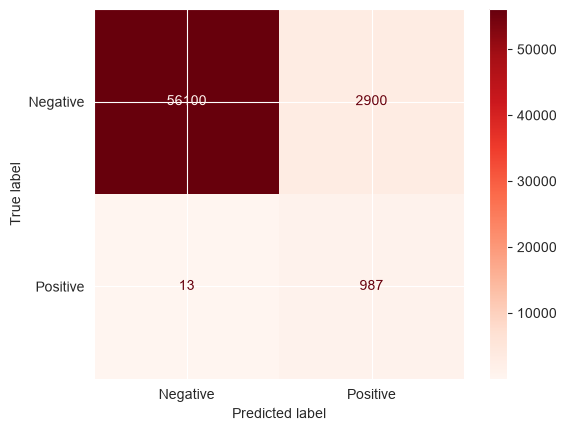

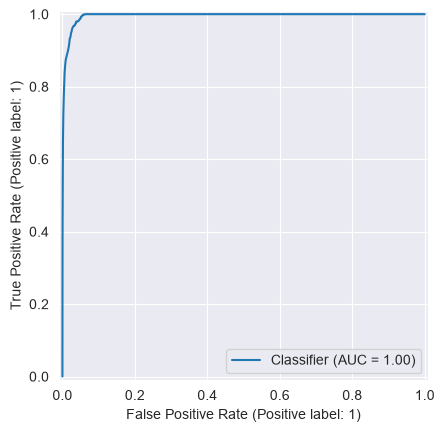

Rebalanced Train AUC: 0.9955952457627119
Rebalanced Train Error: 0.04656249999999995
Rebalanced Train OOB Error: 0.029416666666666647
Train AUC: 1.0
Train Error: 1.666666666666483e-05
Train OOB Error: 0.006166666666666654


In [79]:
bal_forest = BalancedRandomForestClassifier(n_estimators=100, bootstrap=True, oob_score=True, random_state=42, n_jobs=-1)
bal_forest.fit(train_data.drop(columns=['class']), train_data['class'])
predictions = bal_forest.predict(test_data.drop(columns=['class']))

rebalanced_train_error = 1 - accuracy_score(test_data['class'], predictions)
rebalanced_train_oob_error = 1- bal_forest.oob_score_

#Training Confusion Matrix
c_matrix= confusion_matrix(train_data['class'], bal_forest.predict(train_data.drop(columns=['class'])))
disp = ConfusionMatrixDisplay(confusion_matrix=c_matrix, display_labels=['Negative', 'Positive'])
disp.plot(cmap=plt.cm.Reds)
plt.show()

#ROC and AUC
rebalanced_train_scores = bal_forest.predict_proba(train_data.drop(columns=['class']))[:, 1]
rebalanced_train_auc = roc_auc_score(train_data['class'], rebalanced_train_scores)
RocCurveDisplay.from_predictions(train_data['class'], rebalanced_train_scores)
plt.show()
print('Rebalanced Train AUC: ' + str(rebalanced_train_auc))
print('Rebalanced Train Error: ' + str(rebalanced_train_error))
print('Rebalanced Train OOB Error: ' + str(rebalanced_train_oob_error))
print('Train AUC: ' + str(auc))
print('Train Error: ' + str(error))
print('Train OOB Error: ' + str(oob_error))

### (e) XGBoost and Model Trees

Best alpha: 0.01
Train AUC: 0.9999023898305085
CV AUC: 0.9897888559322034


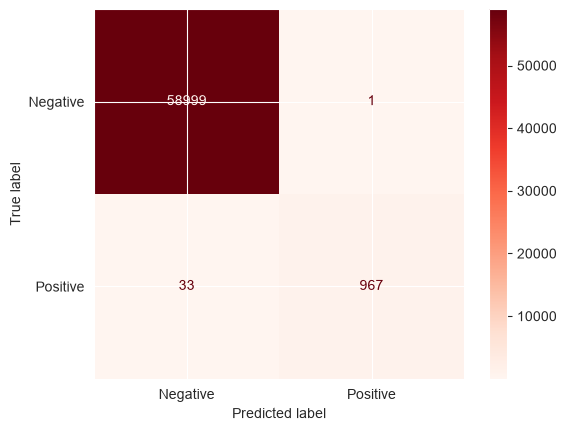

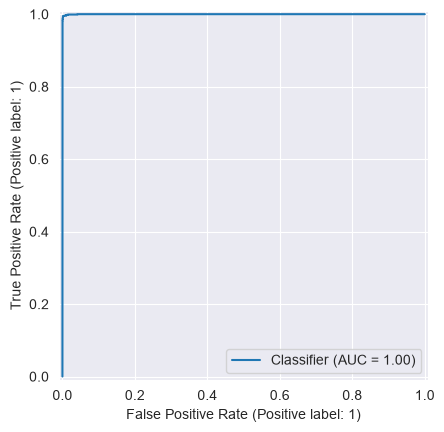

Test results
Test AUC: 0.9954203306666667
CV AUC: 0.9897888559322034


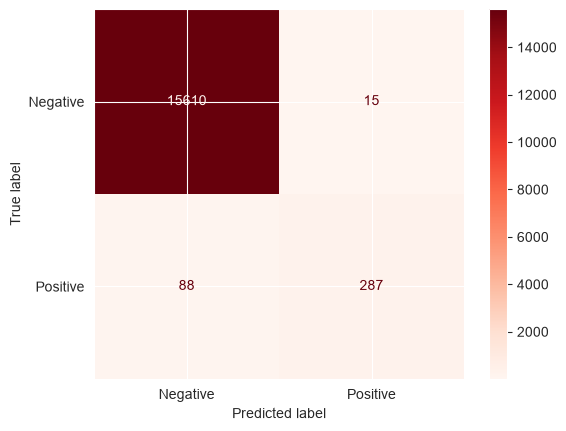

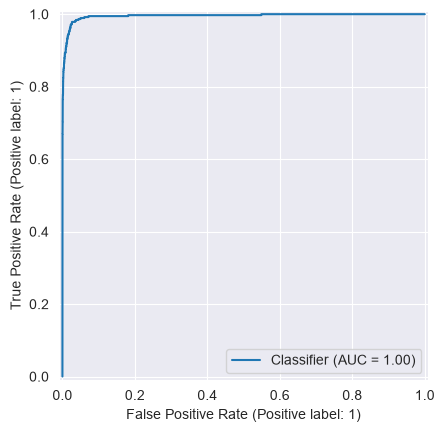

In [80]:
train_x = train_data.drop(columns=['class'])
train_y = train_data['class']
test_x = test_data.drop(columns=['class'])
test_y = test_data['class']

k_fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
xgb = XGBClassifier(random_state=42, learning_rate=0.1, n_estimators=100, tree_method='hist', n_jobs=-1)
parameters = {"reg_alpha": np.logspace(-2, 2, 5)}
XGB_CV = GridSearchCV(cv=k_fold, scoring="roc_auc", estimator=xgb, param_grid=parameters)
XGB_CV.fit(train_x, train_y)

cv_predictions = XGB_CV.predict(train_x)
XGB_CV_AUC = roc_auc_score(train_y, XGB_CV.predict_proba(train_x)[:, 1])
print(f"Best alpha: {XGB_CV.best_params_['reg_alpha']}")
print('Train AUC: ' + str(XGB_CV_AUC))
print('CV AUC: ' + str(XGB_CV.best_score_))


XGB_CV_train_error = 1 - accuracy_score(train_y, cv_predictions)

#Training Confusion Matrix
c_matrix= confusion_matrix(train_y, cv_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=c_matrix, display_labels=['Negative', 'Positive'])
disp.plot(cmap=plt.cm.Reds)
plt.show()

#ROC and AUC
XGB_CV_train_scores = XGB_CV.predict_proba(train_x)[:, 1]
XGB_CV_train_auc = roc_auc_score(train_y, XGB_CV_train_scores)
RocCurveDisplay.from_predictions(train_y, XGB_CV_train_scores)
plt.show()

#Fit Test Data
cv_predictions = XGB_CV.predict(test_x)

#Test Confusion Matrix
print('Test results')
XGB_CV_test_auc = roc_auc_score(test_y, XGB_CV.predict_proba(test_x)[:, 1])
print('Test AUC: ' + str(XGB_CV_test_auc))
print('CV AUC: ' + str(XGB_CV.best_score_))
c_matrix= confusion_matrix(test_y, cv_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=c_matrix, display_labels=['Negative', 'Positive'])
disp.plot(cmap=plt.cm.Reds)
plt.show()

#Test ROC and AUC
XGB_CV_test_scores = XGB_CV.predict_proba(test_x)[:, 1]
XGB_CV_test_auc = roc_auc_score(test_y, XGB_CV_test_scores)
RocCurveDisplay.from_predictions(test_y, XGB_CV_test_scores)
plt.show()



### (f) Use SMOTE to pre-process your data

In [81]:
pipeline = Pipeline([("scaler", StandardScaler()), ("Smote", SMOTE(random_state=42)), ("XGBC", XGBClassifier(random_state=42, learning_rate=0.1, n_estimators=100, tree_method='hist', n_jobs=-1))])
parameters = {"XGBC__reg_alpha": np.logspace(-2, 2, 5)}
val = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_search = GridSearchCV(pipeline, parameters, cv=val, scoring="roc_auc")
grid_search.fit(train_x, train_y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'XGBC__reg_alpha': array([1.e-02...e+01, 1.e+02])}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls 

Best alpha: 0.1
Train AUC: 0.9994923389830508


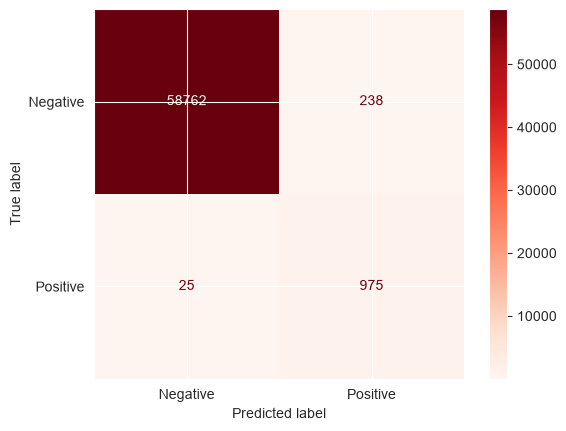

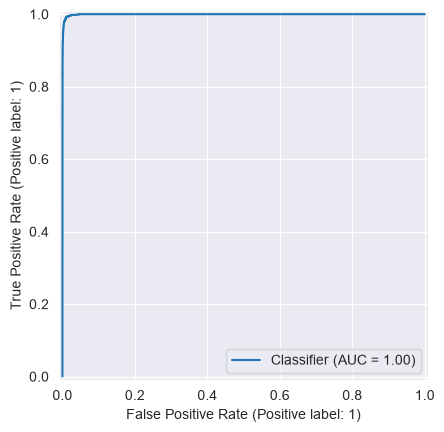

Test results
Test AUC: 0.9942334293333334
CV AUC: 0.9875127542372881


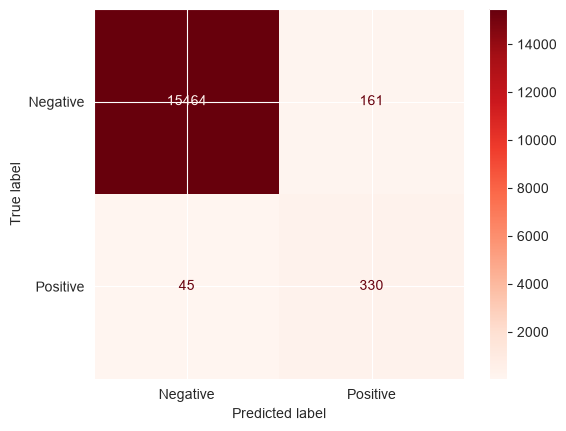

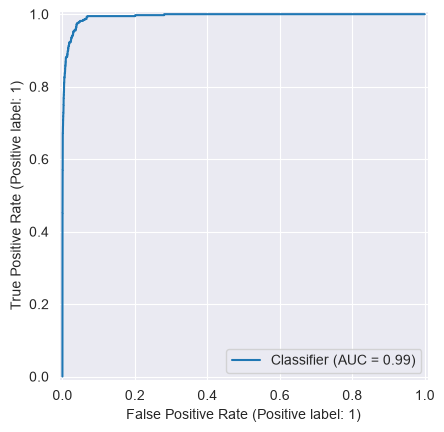

In [82]:
grid_predictions = grid_search.predict(train_x)

grid_AUC = roc_auc_score(train_y, grid_search.predict_proba(train_x)[:, 1])
print(f"Best alpha: {grid_search.best_params_['XGBC__reg_alpha']}")
print('Train AUC: ' + str(grid_AUC))



#Training Confusion Matrix
c_matrix= confusion_matrix(train_y, grid_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=c_matrix, display_labels=['Negative', 'Positive'])
disp.plot(cmap=plt.cm.Reds)
plt.show()

#ROC and AUC
grid_train_scores = grid_search.predict_proba(train_x)[:, 1]
grid_train_auc = roc_auc_score(train_y, grid_train_scores)
RocCurveDisplay.from_predictions(train_y, grid_train_scores)
plt.show()


#Fit Test Data
grid_test_predictions = grid_search.predict(test_x)


#Test Confusion Matrix
print('Test results')
grid_test_auc = roc_auc_score(test_y, grid_search.predict_proba(test_x)[:, 1])
print('Test AUC: ' + str(grid_test_auc))
print('CV AUC: ' + str(grid_search.best_score_))
c_matrix= confusion_matrix(test_y, grid_test_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=c_matrix, display_labels=['Negative', 'Positive'])
disp.plot(cmap=plt.cm.Reds)
plt.show()


#Test ROC and AUC
grid_test_scores = grid_search.predict_proba(test_x)[:, 1]
grid_test_auc = roc_auc_score(test_y, grid_test_scores)
RocCurveDisplay.from_predictions(test_y, grid_test_scores)
plt.show()

The SMOTE case shows slightly lower accuracy, AUC, and true positive/negative. However, it should be noted that both show unusually high accuracy, so minute differences may not be meaningful for this classification task.

## 2. ISLR 6.6.3

a.<br>
    i. False: RSS can only decrease or remain the same when the value of s increases, as the range of possible coefficients increases.
    ii.
        False, same as above<br>
    iii.
        False, same as above<br>
    iv.
        False, same as above<br>
    v.
        False, unless the minimum RSS solution is possible with an s value of 0<br>
b.<br>
    i.
        False, Test RSS will trend downwards until s begins to overfit, approximating noise rather than the function.<br>
    ii.
        False. While it will decrease then increase, it will eventually stop after overfitting to the training data.<br>
    iii.
        False, same as above<br>
    iv.
        False, same as above<br>
    v.
        False, same as above<br>
c.<br>
    i.
        False, models will fit more (eventually overfit), so more variance in performance between training sets will occur<br>
    ii.
        False, same as above<br>
    iii.
        True, same as above <br>
    iv.
        False, same as above <br>
    v.
        False, same as above <br>
d.<br>
    i.
        False, greater s allows for more flexibility in terms of parameters, generally decreasing the bias<br>
    ii.
        False, same as above<br>
    iii.
        False, same as above<br>
    iv.
        True, same as above<br>
    v.
        False, same as above<br>
e. <br>
    i.
        False, irreducible error is a characteristic of the dataset, not the model, so changes to the model do not affect it<br>
    ii.
        False, same as above<br>
    iii.
        False, same as above<br>
    iv.
        False, same as above<br>
    v.
        True, the noise itself is independent of the s value, so it remains constant.

## 3. ISLR 6.6.5

d). Because C is the optimal solution and is the sum of B1 and B2, there can be multiple unique combinations which would sum to C.

## 4. ISLR 8.4.5

When applying the majority vote approach, most of the values of P(Red|X) are > 0.5, so the tree would default to red. The average probability approach would default to green, as the average of the 10 values is less than 0.5.

## 5. ISLR 9.7.3

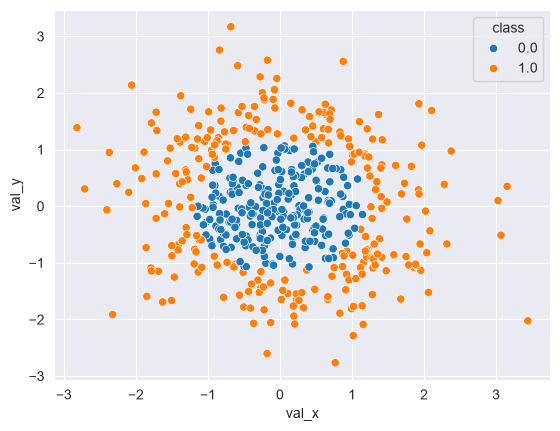

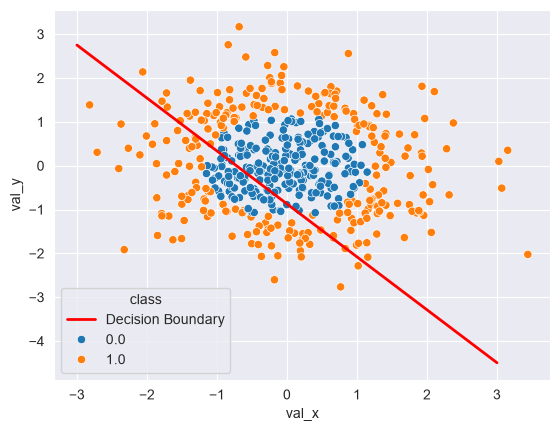

In [128]:
#A
data = np.random.randn(500,3)
df = pd.DataFrame(data, columns=['val_x', 'val_y', 'class'])
for i in range(0,500):
    df.iloc[i,2] = ((df.iloc[i,0]**2 + df.iloc[i,1]**2) > 1.39).astype(int)

#B
sns.scatterplot(hue=df['class'], x=df['val_x'], y=df['val_y'])
plt.show()

#C, D
lr = LogisticRegression()
lr.fit(df.drop(['class'], axis=1), df['class'])
y_pred = lr.predict(df.drop(['class'], axis=1))
b = lr.intercept_[0]
w1, w2 = lr.coef_[0]
x1 = np.array([-3, 3])
x2 = -(w1 * x1 + b) / w2
plt.plot(x1, x2, color="red", linewidth=2, label="Decision Boundary")
sns.scatterplot(hue=df['class'], x=df['val_x'], y=df['val_y'])
plt.show()

#E
df2 = df.copy()
for i in range(0,500):
    df2.iloc[i,1] = df2.iloc[i,1]**2
    df2.iloc[i,0] = df2.iloc[i,0]**2
df2 = df2.rename(columns={"val_x": "x", "val_y": "y"})
df2= df2.drop(['class'], axis=1)
df2 = pd.concat([df2, df.drop('class', axis=1)], axis=1)

